# Lab 7: Naive Bayes — From Scratch to Bayes Optimal
### (Student Worksheet)

**Objective:** Classify sentences from biomedical abstracts into their rhetorical role
(BACKGROUND, OBJECTIVE, METHODS, RESULTS, CONCLUSIONS). You will implement Multinomial Naive
Bayes yourself in NumPy, **verify it against scikit-learn**, and then explore how smoothing,
feature representation and model combination change what the classifier can do.

**Dataset:** PubMed 20k RCT — 180,040 labelled training sentences.

**How this notebook works:** Sections 1-2 are fully worked — run them as-is. From Section 3
onward, cells marked **`# TODO`** give instructions but no solution code. Several TODOs name an
**exact variable or method**, because later cells depend on that name. Work through the
sections in order.

---
## 1. Setup & Your Assignment

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

plt.rcParams["figure.dpi"] = 110

Set `STUDENT_ID` to **your own SRN**. Its last three digits set the size of the training
subsample used in Part C, so your Part C numbers will differ based on SRN.

In [2]:
STUDENT_ID = "PES2UG24CS276"   # <-- CHANGE THIS TO YOUR SRN

last_three = int(STUDENT_ID[-3:])
SAMPLE_SIZE = 10_000 + 276
SEED = 42

print(f"Student ID       : {STUDENT_ID}")
print(f"Part C subsample : {SAMPLE_SIZE:,} training sentences")

Student ID       : PES2UG24CS276
Part C subsample : 10,276 training sentences


---
## 2. Load the Data


Upload `train.txt`, `dev.txt` and `test.txt` from the PubMed 20k RCT dataset next to this
notebook first.

| Split | Purpose |
|---|---|
| **train** | Fits the model — counts the words. |
| **dev** | Chooses hyperparameters (`alpha`, n-gram range). |
| **test** | Scored **once**, at the end. Never used to make a choice. |

In [3]:
import os, urllib.request
base = "https://raw.githubusercontent.com/Franck-Dernoncourt/pubmed-rct/master/PubMed_20k_RCT/"
for f in ["train.txt", "dev.txt", "test.txt"]:
    if not os.path.exists(f):
        print("downloading", f)
        urllib.request.urlretrieve(base + f, f)
print(os.listdir())


downloading dev.txt
downloading test.txt
['test.txt', 'dev.txt', 'train.txt', 'Lab7_Student_Manual.pdf', 'Lab7_NaiveBayes_Exploratory_STUDENT.ipynb']


In [4]:
def load_pubmed_rct_file(filepath):
    """Read one PubMed 20k RCT .txt file into a DataFrame of (label, sentence)."""
    labels, sentences = [], []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or "\t" not in line:
                continue                      # skips '###<id>' lines and blanks
            label, sent = line.split("\t", maxsplit=1)
            labels.append(label)
            sentences.append(sent)
    return pd.DataFrame({"label": labels, "sentence": sentences})


dir_path = "./"
train_df = load_pubmed_rct_file(os.path.join(dir_path, "train.txt"))
dev_df   = load_pubmed_rct_file(os.path.join(dir_path, "dev.txt"))
test_df  = load_pubmed_rct_file(os.path.join(dir_path, "test.txt"))

X_train, y_train = train_df["sentence"], train_df["label"]
X_dev,   y_dev   = dev_df["sentence"],   dev_df["label"]
X_test,  y_test  = test_df["sentence"],  test_df["label"]
target_names = sorted(y_train.unique())

print(f"Train : {len(train_df):,}")
print(f"Dev   : {len(dev_df):,}")
print(f"Test  : {len(test_df):,}")
print(f"Classes: {target_names}")

Train : 44,628
Dev   : 30,212
Test  : 30,135
Classes: ['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS']


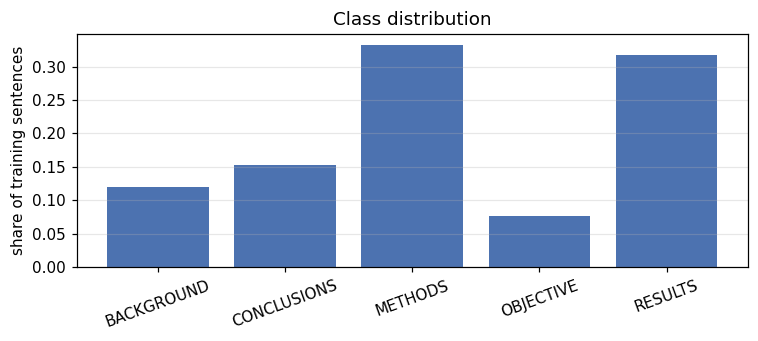

label
BACKGROUND     0.121
CONCLUSIONS    0.153
METHODS        0.332
OBJECTIVE      0.077
RESULTS        0.317

Always-predict-'METHODS' accuracy would be 0.332
Two example sentences:
  [BACKGROUND] Emotional eating is associated with overeating and the development of obesity ....
  [CONCLUSIONS] Low-dose oral prednisolone had both a short-term and a longer sustained effect resulting i...


In [5]:
dist = y_train.value_counts(normalize=True).reindex(target_names)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index, dist.values, color="#4c72b0")
ax.set_ylabel("share of training sentences")
ax.set_title("Class distribution")
ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

print(dist.round(3).to_string())
print(f"\nAlways-predict-'{dist.idxmax()}' accuracy would be {dist.max():.3f}")
print("Two example sentences:")
for lab in target_names[:2]:
    print(f"  [{lab}] {train_df[train_df.label == lab].sentence.iloc[0][:90]}...")

**TODO (reflection):** The classes are far from balanced. Using the number printed above,
explain why plain **accuracy** is a weak way to score this task, and what **macro-averaged F1**
(which averages the per-class F1 scores, weighting every class equally) measures instead.
Which class do you expect to be hardest, and why?

*Your answer:*

---
## 3. Multinomial Naive Bayes, From Scratch

### Concept

Naive Bayes picks the class with the highest posterior probability given the words in the
sentence. By Bayes' rule, and dropping the evidence term (the same for every class):

$$\hat{c} = \arg\max_{c}\; P(c) \prod_{i} P(w_i \mid c)^{x_i}$$

where $x_i$ is how many times word $i$ appears. The "naive" part is that product: it assumes
words are **conditionally independent** given the class, which is plainly false for language
("randomized" and "controlled" are not independent) but works well anyway.

**Everything happens in log space.** A sentence of 25 words multiplies 25 probabilities, each
perhaps $10^{-5}$ — the result underflows to exactly 0.0 in floating point, and every class
ties at zero. Taking logs turns the product into a sum, which is numerically stable and faster:

$$\log P(c) + \sum_i x_i \log P(w_i \mid c)$$

**Laplace (additive) smoothing.** If a word never appears in class $c$ in training, its
probability is 0, the product is 0, and that class is ruled out by a single unseen word — no
matter how strongly the other 24 words support it. Smoothing adds a pseudo-count $\alpha$ to
every word:

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\sum_j \text{count}(w_j, c) + \alpha V}$$

where $V$ is the vocabulary size. The $\alpha V$ in the denominator keeps it a valid
probability distribution. Section 6 asks you to tune $\alpha$.



In [6]:
class NaiveBayesClassifier:
    """Multinomial Naive Bayes with Laplace smoothing, implemented from scratch."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.vocabulary_size_ = X.shape[1]
        n_samples = X.shape[0]

        log_priors, log_likelihoods = [], []
        for c in self.classes_:
            X_c = X[y == c]

            # TODO 1: log prior = log(rows in class / total rows)
            log_priors.append(np.log(X_c.shape[0] / n_samples))

            counts = np.asarray(X_c.sum(axis=0)).ravel()

            # TODO 2: smoothed log likelihood
            num = counts + self.alpha
            den = counts.sum() + self.alpha * self.vocabulary_size_
            log_likelihoods.append(np.log(num / den))

        # TODO 3: stack into arrays
        self.class_log_prior_ = np.array(log_priors)
        self.feature_log_prob_ = np.vstack(log_likelihoods)
        return self

    def predict_log_scores(self, X):
        # TODO 4: one matrix multiply, no loops
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    def predict(self, X):
        # TODO 5: argmax -> label
        return self.classes_[np.argmax(self.predict_log_scores(X), axis=1)]

---
## 4. Build the Features & Verify Your Implementation

First turn sentences into count vectors. `CountVectorizer` is fitted on the **training split
only** — fitting it on everything would let the vocabulary be shaped by sentences the model is
not supposed to have seen.

`min_df=2` drops words appearing in only one sentence across 180,000. Those are typos and
one-off technical terms; keeping them inflates the vocabulary (and therefore the $\alpha V$
smoothing term) without adding signal.

In [7]:
count_vectorizer = CountVectorizer(lowercase=True, strip_accents="unicode",
                                   stop_words="english", ngram_range=(1, 1), min_df=2)
X_train_counts = count_vectorizer.fit_transform(X_train)
X_dev_counts   = count_vectorizer.transform(X_dev)
X_test_counts  = count_vectorizer.transform(X_test)
print("Vocab size:", len(count_vectorizer.vocabulary_))

Vocab size: 18980


### The verification check 



The reason to check this way: **a wrong Naive Bayes still classifies.** Forget the $\alpha V$
term in the denominator and your probabilities no longer sum to one — but they are still
monotone in the counts, so the argmax is often unchanged and accuracy barely moves. Drop the
log prior entirely and you lose a couple of points, which looks like a modelling choice rather
than a bug. Neither failure announces itself.

In [8]:
_mine = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
_skl  = MultinomialNB(alpha=1.0).fit(X_train_counts, y_train)

assert hasattr(_mine, "class_log_prior_"), "fit() never set class_log_prior_"
assert hasattr(_mine, "feature_log_prob_"), "fit() never set feature_log_prob_"
assert _mine.feature_log_prob_.shape == _skl.feature_log_prob_.shape, (
    f"feature_log_prob_ is {_mine.feature_log_prob_.shape}, "
    f"expected {_skl.feature_log_prob_.shape} (n_classes, vocab_size)")

prior_err = np.abs(_mine.class_log_prior_ - _skl.class_log_prior_).max()
lik_err   = np.abs(_mine.feature_log_prob_ - _skl.feature_log_prob_).max()
print(f"Max difference in log priors      : {prior_err:.3e}")
print(f"Max difference in log likelihoods : {lik_err:.3e}")

assert prior_err < 1e-10, (
    "LOG PRIORS DO NOT MATCH. P(c) is the share of training ROWS in class c "
    "(X_c.shape[0] / n_samples) — not the share of word counts.")
assert lik_err < 1e-10, (
    "LOG LIKELIHOODS DO NOT MATCH. Most likely the denominator: it must be "
    "counts.sum() + alpha * vocabulary_size, and the alpha*V term is easy to omit.")

_agree = (_mine.predict(X_test_counts) == _skl.predict(X_test_counts)).mean()
print(f"Prediction agreement on test      : {_agree:.4%}")
assert _agree > 0.999, "Parameters match but predictions do not — check predict()."

print("\nSection 4 checks passed — your implementation is correct.")

Max difference in log priors      : 1.554e-15
Max difference in log likelihoods : 1.776e-15
Prediction agreement on test      : 100.0000%

Section 4 checks passed — your implementation is correct.


**TODO (reflection):** Suppose you had forgotten the `alpha * vocabulary_size` term in the
denominator. The check above would fail, but would the **accuracy** have dropped noticeably?
Reason about what that term does to the scores of each class, and explain why matching a
reference implementation is a stronger test than "the accuracy looks about right".

*Your answer:*

---
## 5. Baseline Evaluation

Train your classifier on the count features and score it on the test set.

In [9]:
RESULTS = []    # every experiment appends one row here


def log_result(name, y_true, y_pred, note="", elapsed=None):
    """Score a set of predictions, print a summary, and record it in RESULTS."""
    row = {
        "Experiment": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 4),
        "Time (s)": None if elapsed is None else round(elapsed, 1),
        "Observations": note,
    }
    RESULTS.append(row)
    print(f"  {name}: accuracy {row['Accuracy']:.4f} | macro-F1 {row['Macro F1']:.4f}")
    return row


def plot_confusion(y_true, y_pred, title):
    """Row-normalised confusion matrix: each row shows where that true class went."""
    cm = confusion_matrix(y_true, y_pred, labels=target_names)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=target_names, yticklabels=target_names,
                vmin=0, vmax=1, cbar_kws={"label": "share of true class"})
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(title)
    plt.tight_layout(); plt.show()


print("Helpers ready.")

Helpers ready.


  Custom NB (counts, alpha=1): accuracy 0.7245 | macro-F1 0.6487
              precision    recall  f1-score   support

  BACKGROUND       0.51      0.52      0.52      3621
 CONCLUSIONS       0.59      0.66      0.62      4571
     METHODS       0.80      0.84      0.82      9897
   OBJECTIVE       0.51      0.44      0.47      2333
     RESULTS       0.85      0.78      0.81      9713

    accuracy                           0.72     30135
   macro avg       0.65      0.65      0.65     30135
weighted avg       0.73      0.72      0.72     30135



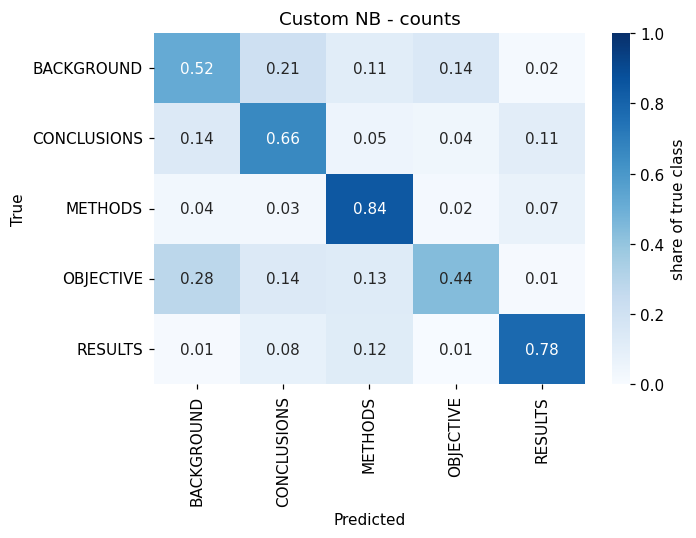

In [10]:
t0 = time.time()
nb_model = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
y_test_pred = nb_model.predict(X_test_counts)
log_result("Custom NB (counts, alpha=1)", y_test, y_test_pred,
           note="Baseline; strong on RESULTS/METHODS, weaker on rare classes",
           elapsed=time.time() - t0)
print(classification_report(y_test, y_test_pred, target_names=target_names))
plot_confusion(y_test, y_test_pred, "Custom NB - counts")

**TODO (reflection):** Look at the row-normalised confusion matrix. Name the two largest
off-diagonal confusions and explain, in terms of the words those classes share, why Naive
Bayes makes them. Does the pattern match what you predicted in Section 2?

*Your answer:*

---
# Part B — Smoothing and Features

## 6. Experiment 1 — The Smoothing Parameter

### Concept

$\alpha$ controls how much probability mass is reserved for words a class has never produced.
Small $\alpha$ trusts the training counts almost completely, so a single unseen word can
dominate the score; large $\alpha$ flattens the word distributions toward uniform, washing out
the differences between classes. Somewhere in between is a best value, and the **dev set** is
where you find it — using the test set to pick $\alpha$ would make the final score a
self-fulfilling one.

alpha=0.01: dev macro-F1 0.6217
alpha=0.1: dev macro-F1 0.6423
alpha=0.5: dev macro-F1 0.6538
alpha=1.0: dev macro-F1 0.6582
alpha=2.0: dev macro-F1 0.6537
best_alpha: 1.0


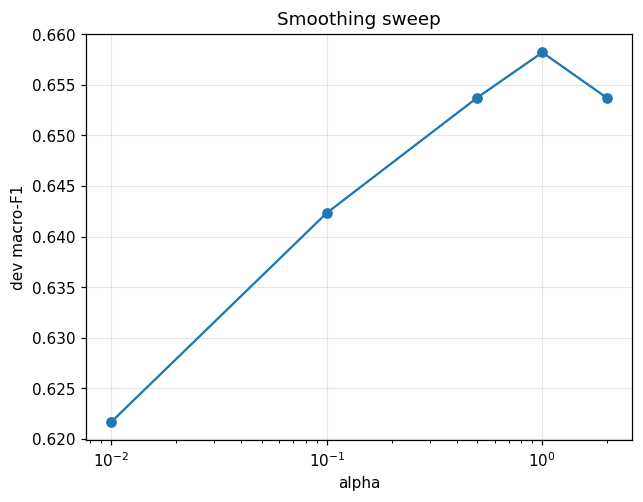

  Custom NB (counts, tuned alpha=1.0): accuracy 0.7245 | macro-F1 0.6487


{'Experiment': 'Custom NB (counts, tuned alpha=1.0)',
 'Accuracy': 0.7245,
 'Macro F1': 0.6487,
 'Time (s)': 0.1,
 'Observations': 'alpha picked on dev, test scored once'}

In [11]:
alpha_scores = {}
for a in [0.01, 0.1, 0.5, 1.0, 2.0]:
    m = NaiveBayesClassifier(alpha=a).fit(X_train_counts, y_train)
    alpha_scores[a] = f1_score(y_dev, m.predict(X_dev_counts), average="macro")
    print(f"alpha={a}: dev macro-F1 {alpha_scores[a]:.4f}")

best_alpha = max(alpha_scores, key=alpha_scores.get)
print("best_alpha:", best_alpha)

plt.plot(list(alpha_scores), list(alpha_scores.values()), "o-")
plt.xscale("log")
plt.xlabel("alpha"); plt.ylabel("dev macro-F1")
plt.title("Smoothing sweep"); plt.grid(alpha=0.3); plt.show()

t0 = time.time()
m = NaiveBayesClassifier(alpha=best_alpha).fit(X_train_counts, y_train)
yp_tuned = m.predict(X_test_counts)
log_result(f"Custom NB (counts, tuned alpha={best_alpha})", y_test, yp_tuned,
           note="alpha picked on dev, test scored once", elapsed=time.time() - t0)

**TODO (reflection):** `alpha=0.01` should score clearly worse than `alpha=1.0`, even though
it fits the training counts more faithfully. Explain what goes wrong when smoothing is too
weak. Then explain why the whole sweep had to run on the dev set — what exactly would be wrong
with the final test number if you had picked `alpha` by testing each value on the test set?

*Your answer:*

---
## 7. Experiment 2 — Counts vs TF-IDF

### Concept

Raw counts treat every occurrence of every word as equally informative. **TF-IDF** rescales
each count by how rare the word is across the corpus, so "patients" — which appears everywhere
and separates nothing — is damped, while a word concentrated in one class keeps its weight.

It is the standard default for text classification, so the interesting question is whether it
actually helps *here*. Note that TF-IDF produces fractional values, not counts, so the
multinomial model is no longer being fed the kind of data its derivation assumes; it still
works, but the justification is now empirical rather than principled.


  TF-IDF + MNB (default): accuracy 0.6884 | macro-F1 0.5339
{'nb__alpha': 0.1, 'tfidf__ngram_range': (1, 2)} 0.6235077061712934
  TF-IDF + MNB (tuned): accuracy 0.7269 | macro-F1 0.6348


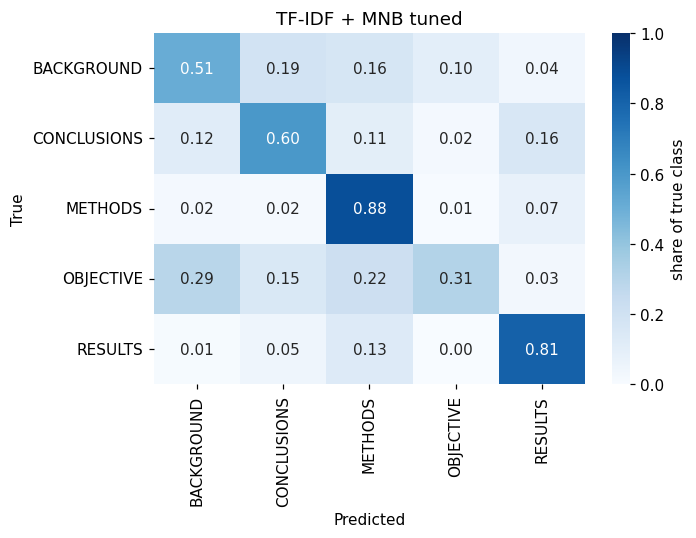

In [12]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode",
                              stop_words="english", min_df=2)),
    ("nb", MultinomialNB())])

# Step 1: default
t0 = time.time()
pipeline.fit(X_train, y_train)
log_result("TF-IDF + MNB (default)", y_test, pipeline.predict(X_test),
           note="Default alpha=1 too heavy for small tf-idf values",
           elapsed=time.time() - t0)

# Step 2: tune on DEV
param_grid = {"tfidf__ngram_range": [(1, 1), (1, 2)],
              "nb__alpha": [0.1, 0.5, 1.0]}
grid = GridSearchCV(pipeline, param_grid, cv=3, scoring="f1_macro", n_jobs=-1)
grid.fit(X_dev, y_dev)
print(grid.best_params_, grid.best_score_)

# Step 3: refit winner on FULL train, score test once
t0 = time.time()
best_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode",
                              stop_words="english", min_df=2)),
    ("nb", MultinomialNB())]).set_params(**grid.best_params_)
best_pipe.fit(X_train, y_train)
yp_tfidf = best_pipe.predict(X_test)
log_result("TF-IDF + MNB (tuned)", y_test, yp_tfidf,
           note=f"Tuned on dev: {grid.best_params_}", elapsed=time.time() - t0)
plot_confusion(y_test, yp_tfidf, "TF-IDF + MNB tuned")

**TODO (reflection):** The **default** TF-IDF model should score *worse* than your plain
count model from Section 6, which is the opposite of what its reputation suggests — and then
tuning should push it past both.

(a) Why does untuned TF-IDF lose to raw counts here? Think about what TF-IDF values look like
compared to counts, and what `alpha=1.0` does to each.

(b) What did adding bigrams buy, and what does it cost?

*Your answer:*

---
# Part C — The Bayes Optimal Classifier

## 8. Combining Hypotheses by Their Posterior

### Concept

Everything so far picks a single model and uses it. The **Bayes Optimal Classifier** says that
is not the best you can do. Rather than committing to one hypothesis $h$, it averages the
predictions of *every* hypothesis, each weighted by how probable that hypothesis is given the
data:

$$P(c \mid x, D) = \sum_{h \in H} P(c \mid x, h)\, P(h \mid D)$$

No classifier using the same hypothesis space can do better on average — which is what
"optimal" means here. The catch is that $H$ is the space of *all* hypotheses, which is
infinite, so the true BOC is not computable. What we build instead is an approximation:
take a handful of trained models as a stand-in for $H$, estimate each one's posterior weight
$P(h \mid D)$, and combine their predicted probabilities by **soft voting**.

**Estimating $P(h \mid D)$.** With equal priors over the four models, $P(h \mid D)$ is
proportional to the likelihood of held-out data under $h$. So: hold out part of the training
sample, compute each model's average log-likelihood of the true labels on it, and turn those
into weights with a softmax. Section 8 also asks you to compute the weights the *exact* way —
with the summed log-likelihood instead of the mean — and compare.

Part C uses a subsample of `SAMPLE_SIZE` training sentences (from your SRN), so these models
are weaker than the full-data models in Parts A and B. Compare them with each other, not with
earlier rows.

In [13]:
tfidf_params = dict(lowercase=True, strip_accents="unicode", stop_words="english",
                    ngram_range=(1, 1), min_df=5)

hypotheses = {
    "NaiveBayes": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                            ("clf", MultinomialNB(alpha=0.5))]),
    "LogisticRegression": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                                    ("clf", LogisticRegression(max_iter=1000,
                                                               random_state=SEED))]),
    "DecisionTree": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", DecisionTreeClassifier(max_depth=20,
                                                             random_state=SEED))]),
    "RandomForest": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", RandomForestClassifier(n_estimators=60, max_depth=25,
                                                             random_state=SEED, n_jobs=-1))]),
}

X_sample = X_train[:SAMPLE_SIZE]
y_sample = y_train[:SAMPLE_SIZE]
print(f"Part C training subsample: {len(X_sample):,} sentences")
print(f"Hypothesis space H: {list(hypotheses)}")

Part C training subsample: 10,276 sentences
Hypothesis space H: ['NaiveBayes', 'LogisticRegression', 'DecisionTree', 'RandomForest']


In [14]:
X_fit, X_held, y_fit, y_held = train_test_split(
    X_sample, y_sample, test_size=0.25, random_state=SEED, stratify=y_sample)

mean_log_lik = {}
for name, model in hypotheses.items():
    model.fit(X_fit, y_fit)
    proba = np.clip(model.predict_proba(X_held), 1e-12, None)
    col = [list(model.classes_).index(l) for l in y_held]
    true_p = proba[np.arange(len(y_held)), col]
    mean_log_lik[name] = np.log(true_p).mean()

lls = np.array([mean_log_lik[n] for n in hypotheses])
w = np.exp(lls - lls.max())
posterior_weights = w / w.sum()

# exact Bayesian version: summed log-likelihood
sum_ll = lls * len(y_held)
w2 = np.exp(sum_ll - sum_ll.max())
summed_weights = w2 / w2.sum()

for i, n in enumerate(hypotheses):
    acc = accuracy_score(y_held, hypotheses[n].predict(X_held))
    print(f"{n:20s} meanLL {lls[i]:.4f} | held acc {acc:.4f} | "
          f"w(mean) {posterior_weights[i]:.4f} | w(sum) {summed_weights[i]:.4f}")

NaiveBayes           meanLL -0.8975 | held acc 0.6691 | w(mean) 0.3316 | w(sum) 0.0000
LogisticRegression   meanLL -0.8636 | held acc 0.6898 | w(mean) 0.3430 | w(sum) 1.0000
DecisionTree         meanLL -2.4828 | held acc 0.5033 | w(mean) 0.0679 | w(sum) 0.0000
RandomForest         meanLL -1.1508 | held acc 0.5773 | w(mean) 0.2574 | w(sum) 0.0000


In [15]:
t0 = time.time()
boc = VotingClassifier(estimators=list(hypotheses.items()), voting="soft",
                       weights=list(posterior_weights), n_jobs=-1)
boc.fit(X_sample, y_sample)
log_result("BOC (soft vote, mean-LL weights)", y_test, boc.predict(X_test),
           note="Posterior-weighted ensemble", elapsed=time.time() - t0)

for name, model in hypotheses.items():
    t0 = time.time()
    model.fit(X_sample, y_sample)
    log_result(f"Part C: {name}", y_test, model.predict(X_test),
               note="Individual member on subsample", elapsed=time.time() - t0)

  BOC (soft vote, mean-LL weights): accuracy 0.7034 | macro-F1 0.5944
  Part C: NaiveBayes: accuracy 0.6870 | macro-F1 0.5584
  Part C: LogisticRegression: accuracy 0.7157 | macro-F1 0.6284
  Part C: DecisionTree: accuracy 0.5129 | macro-F1 0.3739
  Part C: RandomForest: accuracy 0.5837 | macro-F1 0.3981


**TODO (reflection):** Two things here, and the second is the important one.

(a) Compare the BOC's macro-F1 against each individual hypothesis. Did the ensemble beat all of
its members? If not, look at the weights — which models received substantial weight, and how
did they perform alone?

(b) The two weight calculations give very different answers: the mean-log-likelihood softmax
spreads weight across the models, while the summed version puts essentially **all** of it on
one. The summed version is the mathematically correct $P(h \mid D)$. Explain why it collapses,
what that collapse implies about the Bayes Optimal Classifier when $H$ contains only a handful
of hypotheses, and which of the two would have scored better here.

*Your answer:*

---
## 9. Results Table

In [16]:
results_df = pd.DataFrame(RESULTS).sort_values("Macro F1", ascending=False)
try:
    display(results_df)
except NameError:
    print(results_df.to_string(index=False))
results_df.to_csv("lab7_results.csv", index=False)

,Experiment,Accuracy,Macro F1,Time (s),Observations
0,"Custom NB (counts, alpha=1)",0.7245,0.6487,0.1,"Baseline; strong on RESULTS/METHODS, weaker on..."
1,"Custom NB (counts, tuned alpha=1.0)",0.7245,0.6487,0.1,"alpha picked on dev, test scored once"
3,TF-IDF + MNB (tuned),0.7269,0.6348,3.0,"Tuned on dev: {'nb__alpha': 0.1, 'tfidf__ngram..."
6,Part C: LogisticRegression,0.7157,0.6284,10.7,Individual member on subsample
4,"BOC (soft vote, mean-LL weights)",0.7034,0.5944,3.3,Posterior-weighted ensemble
5,Part C: NaiveBayes,0.6870,0.5584,0.7,Individual member on subsample
2,TF-IDF + MNB (default),0.6884,0.5339,1.5,Default alpha=1 too heavy for small tf-idf values
8,Part C: RandomForest,0.5837,0.3981,1.2,Individual member on subsample
7,Part C: DecisionTree,0.5129,0.3739,1.3,Individual member on subsample


---
## 10. Reflection

Answer each in 3-5 sentences, referring to **your own numbers**.

1. **Naive Bayes assumes words are conditionally independent given the class, which is plainly
   false for real language.** Give a concrete example of two words in this dataset that are
   obviously dependent, explain what the model does wrong because of it, and suggest why the
   classifier still works reasonably well despite the assumption being violated.

   *Your answer:*

2. **Rank the three things you varied — smoothing strength, feature representation, and model
   combination — by how much each changed your macro-F1.** Which gave the best return for the
   effort involved?

   *Your answer:*

3. **The dev set was used to choose `alpha` and the n-gram range; the test set was scored only
   after those choices were fixed.** Explain what would have been wrong with the reported test
   figure if you had used the test set for tuning, and why the problem is not fixed by the test
   set being large.

   *Your answer:*

4. **You verified your implementation against scikit-learn before measuring its accuracy.**
   Describe one bug that check would catch which a reasonable-looking accuracy score would not,
   and explain why that kind of silent error is harder to find in a classifier than a crash.

   *Your answer:*